# 03 · Analyse one C2 run

Loads `c2_output.json`, `search_history.parquet` and `reasoning_log.json` of a run. Set `RUN_ID` to the run shown in the dashboard, or leave it `None` for the latest run.

In [1]:
import json, ast, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from c2_automl.config import OUTPUT_DIR
from c2_automl.io.dummy_c1 import load_c1_output, load_split

# Validated light palette (same colours as the dashboard)
FAMILY_COLORS = {"random_forest": "#2a78d6", "xgboost": "#eb6834", "lightgbm": "#1baf7a",
                 "catboost": "#eda100", "logistic_regression": "#e87ba4", "ridge": "#008300"}
ROUND_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#184f95", 4: "#0d366b"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
                     "font.size": 10, "lines.linewidth": 2})

In [2]:
RUN_ID = None   # e.g. "diabetes_c2_20261016_225921"

outputs = sorted(glob.glob(str(OUTPUT_DIR / "*" / "*" / "c2_output.json")), key=lambda p: Path(p).stat().st_mtime)
path = next(p for p in outputs if RUN_ID in p) if RUN_ID else outputs[-1]
run_dir = Path(path).parent
out = json.loads(Path(path).read_text())
hist = pd.read_parquet(run_dir / "search_history.parquet")
log = json.loads((run_dir / "reasoning_log.json").read_text())
print(out["run_id"], "| selected:", out["model_family"], "| rounds:", out["rounds"], "| stop:", out.get("stop_reason"))
pd.Series(out["metrics_holdout"]).round(4).to_frame("hold-out")

diabetes_c2_20261022_122409 | selected: logistic_regression | rounds: 2 | stop: max_rounds


,hold-out
accuracy,0.7208
roc_auc,0.8215
f1,0.5567
precision,0.6279
recall,0.5000


## Best CV score per family and round

In [3]:
best = hist[hist.state == "COMPLETE"].sort_values("mean_val").groupby(["family", "round"]).tail(1)
best.pivot(index="family", columns="round", values="mean_val").round(4)

round,1,2
family,,
catboost,0.8306,0.8323
logistic_regression,0.8332,0.8332
random_forest,0.8324,0.8324


## Overfitting gap per round (train − validation of the best trial)
The adaptive loop should shrink the gap of families diagnosed as `overfitting`.

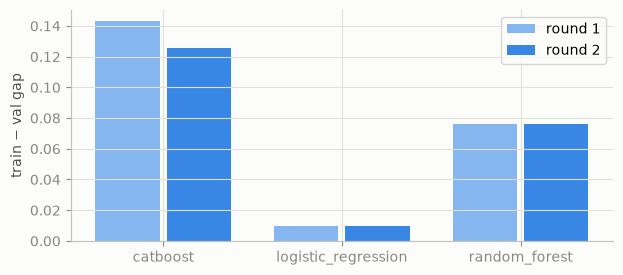

In [4]:
gap = best.pivot(index="family", columns="round", values="gap")
fig, ax = plt.subplots(figsize=(7, 3))
width = 0.8 / len(gap.columns)
for i, rnd in enumerate(gap.columns):
    ax.bar([x + i * width for x in range(len(gap))], gap[rnd].values, width=width * 0.9,
           color=ROUND_COLORS.get(rnd, "#184f95"), label=f"round {rnd}")
ax.set_xticks([x + width * (len(gap.columns) - 1) / 2 for x in range(len(gap))], gap.index)
ax.set_ylabel("train − val gap"); ax.legend(); plt.show()

## Search history

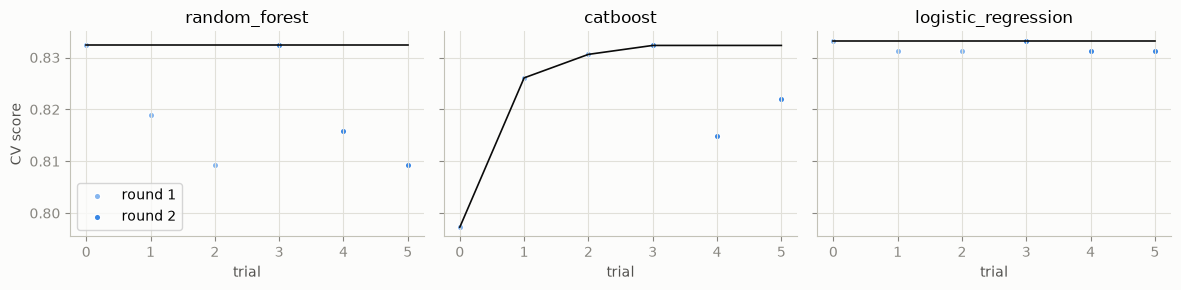

In [5]:
families = list(hist.family.unique())
fig, axes = plt.subplots(1, len(families), figsize=(4 * len(families), 3), sharey=True)
axes = [axes] if len(families) == 1 else axes
for ax, fam in zip(axes, families):
    d = hist[hist.family == fam].reset_index(drop=True)
    for rnd, g in d.groupby("round"):
        done = g[g.state == "COMPLETE"]
        ax.scatter(done.index, done.mean_val, s=22, color=ROUND_COLORS.get(rnd, "#184f95"), label=f"round {rnd}", edgecolor="white")
    ax.plot(d.index, d.mean_val.fillna(d.mean_val.min()).cummax(), color="#0b0b0b", linewidth=1.2)
    ax.set_title(fam); ax.set_xlabel("trial")
axes[0].set_ylabel("CV score"); axes[0].legend(); plt.tight_layout(); plt.show()

## Diagnoses and range changes (from the reasoning log)

In [6]:
diag = pd.DataFrame([{"round": e["round"], "family": e["decision"]["family"], "labels": ", ".join(e["decision"]["labels"]),
                      "why": e["rationale"]} for e in log if e["step"] == "diagnose"])
diag

,round,family,labels,why
0,1,random_forest,healthy,no rule triggered
1,1,catboost,overfitting,train-validation gap 0.143 > 0.05 with train s...
2,1,logistic_regression,healthy,no rule triggered
3,2,random_forest,healthy,no rule triggered
4,2,catboost,overfitting,train-validation gap 0.126 > 0.05 with train s...
5,2,logistic_regression,healthy,no rule triggered


In [7]:
changes = [{"round": e["round"], "family": f, "change": c}
           for e in log if e["step"] == "adapt_spaces" for f, cs in e["decision"]["changes"].items() for c in cs]
pd.DataFrame(changes) if changes else "No range changes in this run"

,round,family,change
0,2,random_forest,max_depth.high 20 -> 30 (best value at range e...
1,2,catboost,l2_leaf_reg.low 1 -> 2 (increase_regularization)
2,2,catboost,l2_leaf_reg.high 10 -> 20 (increase_regulariza...
3,2,catboost,depth.high 8 -> 6 (shrink_depth_range)
4,2,catboost,learning_rate.low 0.01 -> 0.00666667 (best val...
